# QuickCart Stockout Risk - Minor_Project 07


## 1. Problem statement
QuickCart has 12 stores, 60 products and 15 suppliers. If stock runs out, sales are lost. If we order too much, money is wasted.
We predict the risk level for each product, store and day.

## 2. Datas
| File | Rows |
|---|---:|
| dim_stores.csv | 12 |
| dim_skus.csv | 60 |
| dim_suppliers.csv | 15 |
| dim_events.csv | 30 |
| fact_inventory_daily.csv | 21,600 |

the Target: `stockout_risk` - Safe 65.42%, At-Risk 24.01%, Imminent 10.57%.
Imminent is the smallest class but the most important one.

## 3. Importing required libraries

seaborn:makes charts look better with less code

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, precision_score, f1_score
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 4. Load the data
`N/A` in the supplier file is read as missing.

loading all 5 csv files

In [5]:
stores = pd.read_csv("dim_stores.csv")
skus = pd.read_csv("dim_skus.csv")
suppliers = pd.read_csv(
    "dim_suppliers.csv",
    na_values=["N/A", "missing", "--", "NA", "null"],
    keep_default_na=True
)
events = pd.read_csv("dim_events.csv", parse_dates=["date"])
inventory = pd.read_csv("fact_inventory_daily.csv", parse_dates=["date"])

print("Stores:", stores.shape)
print("Products:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Daily inventory:", inventory.shape)

Stores: (12, 8)
Products: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Daily inventory: (21600, 16)


## 5. Check data
Comparimg the row counts with the spec.

In [33]:
expected_rows = {
    "stores": 12,
    "skus": 60,
    "suppliers": 15,
    "events": 30,
    "inventory": 21600
}

actual_rows = {
    "stores": len(stores),
    "skus": len(skus),
    "suppliers": len(suppliers),
    "events": len(events),
    "inventory": len(inventory)
}

for name, expected in expected_rows.items():
    print(f"{name}: {actual_rows[name]} rows (expected {expected})")

print("\nMissing values in inventory:")
display(inventory.isna().sum().to_frame("Missing values"))

print("\nDuplicate rows in inventory:", inventory.duplicated().sum())

stores: 12 rows (expected 12)
skus: 60 rows (expected 60)
suppliers: 15 rows (expected 15)
events: 30 rows (expected 30)
inventory: 21600 rows (expected 21600)

Missing values in inventory:


,Missing values
date,0
store_id,0
sku_id,0
supplier_id,0
opening_stock,0
units_demanded,0
units_sold,0
closing_stock,0
reorder_point,0
reorder_placed,0



Duplicate rows in inventory: 0


## 6. Clean data
- Fix the capital letters in `city_display`.
- Make `reliability_score` numeric (`N/A` becomes missing, filled later with the median).

In [7]:
stores["city_display"] = stores["city_display"].astype("string").str.strip().str.title()
suppliers["reliability_score"] = pd.to_numeric(
    suppliers["reliability_score"], errors="coerce"
)

print("Missing supplier reliability scores:",
      suppliers["reliability_score"].isna().sum())

display(stores.head())
display(suppliers.head())

Missing supplier reliability scores: 3


,store_id,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders
0,ST01,Mumbai,Mumbai,Tier1,Large,2946,2023,580
1,ST02,Mumbai,Mumbai,Tier1,Small,1482,2024,235
2,ST03,Bengaluru,Bengaluru,Tier1,Large,3650,2022,552
3,ST04,Bengaluru,Bengaluru,Tier1,Large,4198,2025,524
4,ST05,Delhi,Delhi,Tier1,Medium,2220,2022,343


,supplier_id,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days
0,SUP01,Fresh Farms Co,Fruits & Vegetables,0.92,5,0.8
1,SUP02,Green Valley Distributors,Snacks,0.93,3,0.8
2,SUP03,Metro Dairy Supplies,Snacks,0.90,2,1.7
3,SUP04,Sunrise Agro Traders,"Beverages, Dairy",0.70,1,0.7
4,SUP05,National Snacks Ltd,Home Care,0.66,2,2.2


## 7. Join tables
Start from the daily table and add store, product, supplier and event details.

In [8]:
data = inventory.merge(stores, on="store_id", how="left")
data = data.merge(skus, on=["sku_id", "supplier_id"], how="left")
data = data.merge(suppliers, on="supplier_id", how="left")
data = data.merge(events, on="date", how="left", suffixes=("", "_event"))

print("Combined dataset shape:", data.shape)
display(data.head())

Combined dataset shape: (21600, 39)


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders,sku_name,category,unit_price_inr,shelf_life_days,is_perishable,festive_relevant,popularity_tier,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


## 8. Check the joined data

In [9]:
print("Target values:")
display(data["stockout_risk"].value_counts(dropna=False))

print("\nMissing values after joining:")
display(data.isna().sum().sort_values(ascending=False).head(20).to_frame("Missing values"))

print("\nDate range:", data["date"].min(), "to", data["date"].max())
print("Unique dates:", data["date"].nunique())

Target values:


,count
stockout_risk,
Safe,14131
At-Risk,5186
Imminent,2283



Missing values after joining:


,Missing values
lead_time_days_actual,19899
reliability_score,5040
date,0
supplier_id,0
opening_stock,0
store_id,0
sku_id,0
units_sold,0
units_demanded,0
reorder_placed,0



Date range: 2026-10-01 00:00:00 to 2026-10-30 00:00:00
Unique dates: 30


## 9. Target classes
Safe is the biggest class, Imminent the smallest.

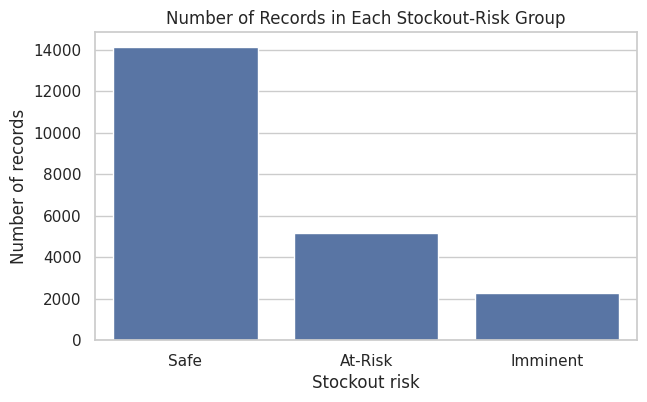

,Percentage
stockout_risk,
Safe,65.42
At-Risk,24.01
Imminent,10.57


In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="stockout_risk",
              order=["Safe", "At-Risk", "Imminent"])
plt.title("Number of Records in Each Stockout-Risk Group")
plt.xlabel("Stockout risk")
plt.ylabel("Number of records")
plt.show()

display((data["stockout_risk"].value_counts(normalize=True) * 100)
        .round(2).rename("Percentage"))

## 10. Festival effect - AI assist
Diwali week is 22-26 Oct. Compare the Imminent rate with other days (spec: 9.51% vs 23.31%).

,is_festival_week,Imminent rate (%)
0,N,9.511633
1,Y,23.309179


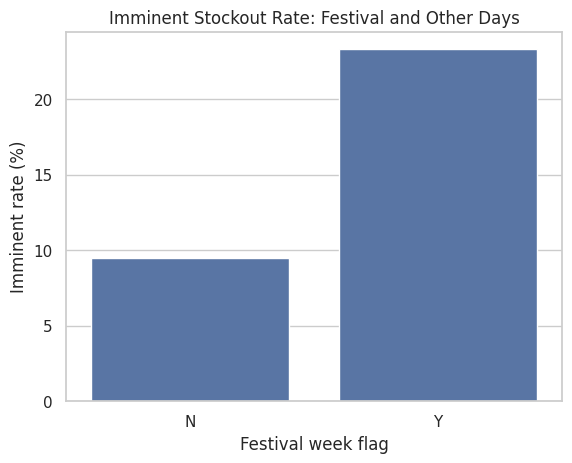

In [11]:
data["is_festival_week"] = data["is_festival_week"].astype(str).str.upper()

festival_summary = (
    data.assign(is_imminent=data["stockout_risk"].eq("Imminent"))
        .groupby("is_festival_week")["is_imminent"]
        .mean()
        .mul(100)
        .reset_index(name="Imminent rate (%)")
)

display(festival_summary)

sns.barplot(data=festival_summary, x="is_festival_week",
            y="Imminent rate (%)")
plt.title("Imminent Stockout Rate: Festival and Other Days")
plt.xlabel("Festival week flag")
plt.ylabel("Imminent rate (%)")
plt.show()

## 11. Supplier reliability
Spec: low 15.83%, medium 6.30%, high 3.82%.
The 3 N/A suppliers get their own "Unknown" group, so Medium shows about 3.26%. The spec's 6.30% most likely includes them.

,reliability_group,Imminent rate (%)
0,High,3.819444
1,Low,15.833333
2,Medium,3.263889
3,Unknown,7.162698


Medium + Unknown together: 6.3 %


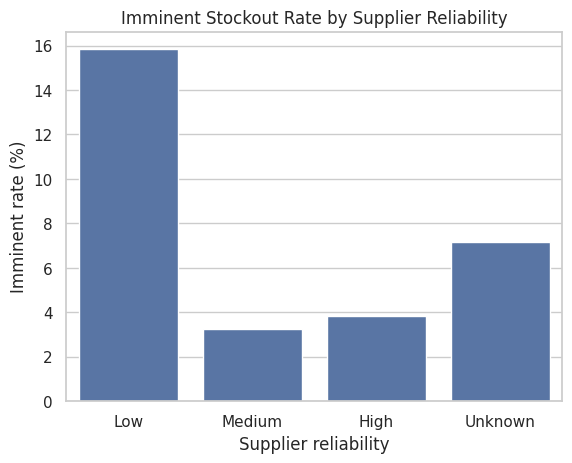

In [12]:
def reliability_group(value):
    if pd.isna(value):
        return "Unknown"
    if value < 0.75:
        return "Low"
    if value < 0.85:
        return "Medium"
    return "High"

data["reliability_group"] = data["reliability_score"].apply(reliability_group)

supplier_summary = (
    data.assign(is_imminent=data["stockout_risk"].eq("Imminent"))
        .groupby("reliability_group")["is_imminent"]
        .mean()
        .mul(100)
        .reset_index(name="Imminent rate (%)")
)

display(supplier_summary)

# Spec's medium group probably includes the Unknown suppliers
mid_unknown = data.loc[data["reliability_group"].isin(["Medium", "Unknown"]), "stockout_risk"].eq("Imminent").mean() * 100
print("Medium + Unknown together:", round(mid_unknown, 2), "%")

sns.barplot(data=supplier_summary, x="reliability_group",
            y="Imminent rate (%)",
            order=["Low", "Medium", "High", "Unknown"])
plt.title("Imminent Stockout Rate by Supplier Reliability")
plt.xlabel("Supplier reliability")
plt.ylabel("Imminent rate (%)")
plt.show()

## 12. Perishable vs non-perishable
Spec: 9.3% vs 12.8%.

,is_perishable,Imminent rate (%)
0,N,9.298246
1,Y,12.765152


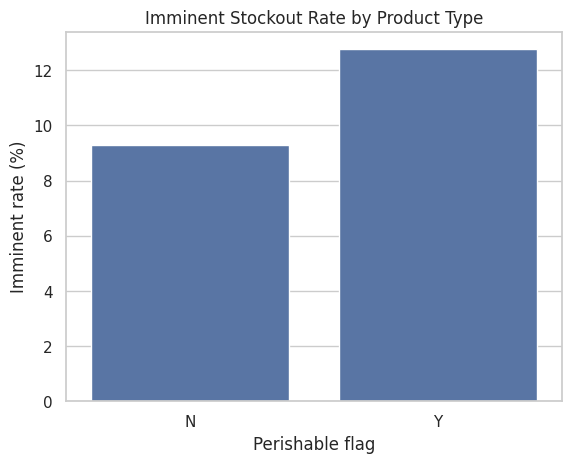

In [13]:
perishable_summary = (
    data.assign(is_imminent=data["stockout_risk"].eq("Imminent"))
        .groupby("is_perishable")["is_imminent"]
        .mean()
        .mul(100)
        .reset_index(name="Imminent rate (%)")
)

display(perishable_summary)

sns.barplot(data=perishable_summary, x="is_perishable",
            y="Imminent rate (%)")
plt.title("Imminent Stockout Rate by Product Type")
plt.xlabel("Perishable flag")
plt.ylabel("Imminent rate (%)")
plt.show()

## 13. New features
- `reorder_gap`, `days_of_cover_ratio`
- `day_of_month`, `days_since_festival_start`
- `is_recent_reorder` (an order in the last 3 days)

In [14]:
data = data.sort_values(["store_id", "sku_id", "date"]).copy()

data["reorder_gap"] = data["reorder_point"] - data["closing_stock"]

data["days_of_cover_ratio"] = (
    data["days_of_cover"] / data["lead_time_days_expected"].replace(0, np.nan)
)

data["day_of_month"] = data["date"].dt.day

festival_start = pd.Timestamp("2026-10-22")
data["days_since_festival_start"] = (data["date"] - festival_start).dt.days
data["days_since_festival_start"] = data["days_since_festival_start"].clip(lower=0)

# Was an order placed in the previous 3 days? (Y/N -> 1/0 first)
data["reorder_flag"] = (data["reorder_placed"] == "Y").astype(int)
data["is_recent_reorder"] = (
    data.groupby(["store_id", "sku_id"])["reorder_flag"]
        .transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum())
        .fillna(0)
        .gt(0)
        .astype(int)
)

display(data[[
    "store_id", "sku_id", "date", "reorder_gap",
    "days_of_cover_ratio", "day_of_month",
    "days_since_festival_start", "is_recent_reorder"
]].head())

,store_id,sku_id,date,reorder_gap,days_of_cover_ratio,day_of_month,days_since_festival_start,is_recent_reorder
0,ST01,SKU001,2026-10-01,-108.5,9.66,1,0,0
1,ST01,SKU001,2026-10-02,-98.5,10.79,2,0,0
2,ST01,SKU001,2026-10-03,-83.5,8.99,3,0,0
3,ST01,SKU001,2026-10-04,-73.5,8.79,4,0,0
4,ST01,SKU001,2026-10-05,-64.5,8.55,5,0,0


## 14. Prepare data
- Target: `stockout_risk`.
- Left out: `lead_time_days_actual` (92% missing), IDs and name columns.
- Time split: train 1-23 Oct, test 24-30 Oct (no random split, to avoid leakage).

In [15]:
target = "stockout_risk"

# Keep rows with a known target.
model_data = data.dropna(subset=[target]).copy()

# Columns we do not use as inputs (IDs, names, text labels).
drop_columns = [
    target,
    "lead_time_days_actual",
    "date",
    "city_display",
    "supplier_name",
    "sku_name",
    "store_id",
    "sku_id",
    "supplier_id",
    "reorder_flag"
]

X = model_data.drop(columns=drop_columns, errors="ignore")
y = model_data[target]

train_mask = model_data["date"] <= pd.Timestamp("2026-10-23")
test_mask = model_data["date"] >= pd.Timestamp("2026-10-24")

X_train = X.loc[train_mask].drop(columns=["date"], errors="ignore")
X_test = X.loc[test_mask].drop(columns=["date"], errors="ignore")
y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training dates:", model_data.loc[train_mask, "date"].min(),
      "to", model_data.loc[train_mask, "date"].max())
print("Testing dates:", model_data.loc[test_mask, "date"].min(),
      "to", model_data.loc[test_mask, "date"].max())

Training rows: 16560
Testing rows: 5040
Training dates: 2026-10-01 00:00:00 to 2026-10-23 00:00:00
Testing dates: 2026-10-24 00:00:00 to 2026-10-30 00:00:00


## 15. Preprocessing
Numbers: fill missing with the median, then scale.
Text: fill with the most common value, then one-hot encode.

In [16]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'lead_time_days_expected', 'sales_velocity_7d', 'days_of_cover', 'sqft', 'opened_year', 'baseline_daily_orders', 'unit_price_inr', 'shelf_life_days', 'reliability_score', 'base_lead_time_days', 'lead_time_variance_days', 'demand_multiplier_festive', 'demand_multiplier_other', 'reorder_gap', 'days_of_cover_ratio', 'day_of_month', 'days_since_festival_start', 'is_recent_reorder']
Categorical features: ['reorder_placed', 'is_festival_week', 'city', 'city_tier', 'store_size', 'category', 'is_perishable', 'festive_relevant', 'popularity_tier', 'categories_supplied', 'event_name', 'event_type', 'reliability_group']


## 16. Baseline
Always predicts the most common class. Other models must beat it.

In [17]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

print("Baseline accuracy:", round(
    accuracy_score(y_test, baseline_predictions), 4
))
print(classification_report(
    y_test, baseline_predictions, zero_division=0
))

Baseline accuracy: 0.6228
              precision    recall  f1-score   support

     At-Risk       0.00      0.00      0.00      1126
    Imminent       0.00      0.00      0.00       775
        Safe       0.62      1.00      0.77      3139

    accuracy                           0.62      5040
   macro avg       0.21      0.33      0.26      5040
weighted avg       0.39      0.62      0.48      5040



## 17. Logistic Regression
Class weights stop the small Imminent class from being ignored.

In [18]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, logistic_predictions), 4))
print(classification_report(
    y_test, logistic_predictions, zero_division=0
))

Logistic Regression accuracy: 0.879
              precision    recall  f1-score   support

     At-Risk       0.97      0.48      0.64      1126
    Imminent       0.58      0.98      0.73       775
        Safe       0.99      1.00      0.99      3139

    accuracy                           0.88      5040
   macro avg       0.84      0.82      0.79      5040
weighted avg       0.92      0.88      0.87      5040



## 18. Random Forest


In [19]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))
print(classification_report(
    y_test, rf_predictions, zero_division=0
))

Random Forest accuracy: 0.9327
              precision    recall  f1-score   support

     At-Risk       0.79      0.94      0.86      1126
    Imminent       0.90      0.65      0.75       775
        Safe       1.00      1.00      1.00      3139

    accuracy                           0.93      5040
   macro avg       0.90      0.86      0.87      5040
weighted avg       0.94      0.93      0.93      5040



## 19. Compare models
Main metric: **recall for Imminent**. Missing a real stockout costs more than a false alarm.

,Accuracy,Macro F1,Recall Safe,Recall At-Risk,Recall Imminent,Precision Imminent
Model,,,,,,
Baseline,0.623,0.256,1.000,0.000,0.000,0.000
Logistic Regression,0.879,0.787,0.997,0.477,0.985,0.579
Random Forest,0.933,0.871,0.999,0.945,0.646,0.899


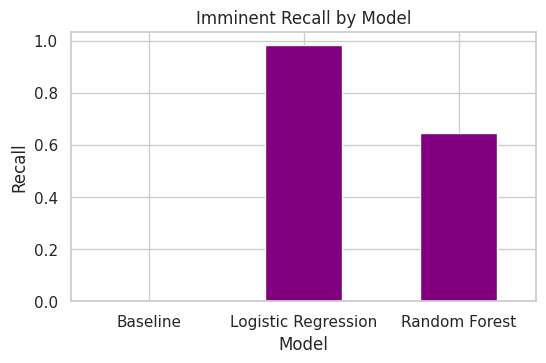

In [32]:
labels = ["Safe", "At-Risk", "Imminent"]

def score_row(name, y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    prec = precision_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Recall Safe": rec[0],
        "Recall At-Risk": rec[1],
        "Recall Imminent": rec[2],
        "Precision Imminent": prec[2],
    }

results = pd.DataFrame([
    score_row("Baseline", y_test, baseline_predictions),
    score_row("Logistic Regression", y_test, logistic_predictions),
    score_row("Random Forest", y_test, rf_predictions),
]).set_index("Model")

display(results.round(3))

results["Recall Imminent"].plot(kind="bar", color="purple", figsize=(6, 3.5))
plt.title("Imminent Recall by Model")
plt.ylabel("Recall")
plt.xticks(rotation=0)
plt.show()

## 20. Confusion matrix
Shown for the model with the best Imminent recall.

Selected model: Logistic Regression


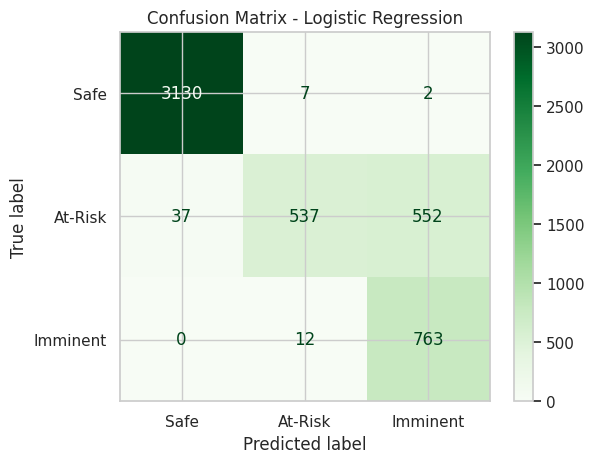

              precision    recall  f1-score   support

        Safe       0.99      1.00      0.99      3139
     At-Risk       0.97      0.48      0.64      1126
    Imminent       0.58      0.98      0.73       775

    accuracy                           0.88      5040
   macro avg       0.84      0.82      0.79      5040
weighted avg       0.92      0.88      0.87      5040



In [30]:
# Pick the model with the best Imminent recall (not the baseline)
models = {
    "Logistic Regression": (logistic_model, logistic_predictions),
    "Random Forest": (random_forest_model, rf_predictions),
}
best_name = results.loc[list(models), "Recall Imminent"].idxmax()
selected_model, selected_predictions = models[best_name]
print("Selected model:", best_name)

cm = confusion_matrix(y_test, selected_predictions, labels=labels)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
cm_display.plot(cmap="Greens", values_format="d")
plt.title("Confusion Matrix - " + best_name)
plt.show()

print(classification_report(
    y_test, selected_predictions, labels=labels, zero_division=0
))

## 21. Feature importance
Top 10 features in the Random Forest.

,Feature,Importance
7,numeric__days_of_cover,0.211470
19,numeric__days_of_cover_ratio,0.170466
18,numeric__reorder_gap,0.156419
3,numeric__closing_stock,0.066986
0,numeric__opening_stock,0.035812
6,numeric__sales_velocity_7d,0.029534
22,numeric__is_recent_reorder,0.023444
4,numeric__reorder_point,0.022973
20,numeric__day_of_month,0.019610
2,numeric__units_sold,0.019252


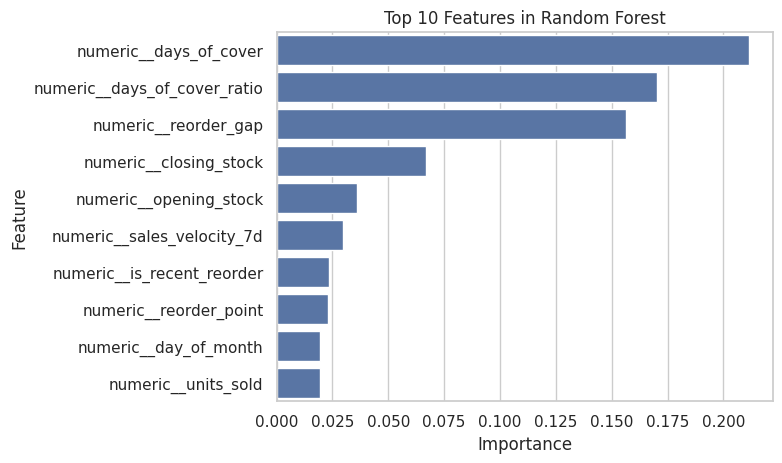

In [22]:
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False).head(10)

display(importance)

sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Top 10 Features in Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## Extra check: without stock columns


In [23]:
leak_cols = ["closing_stock", "days_of_cover", "days_of_cover_ratio", "reorder_gap"]
X_train_nl = X_train.drop(columns=leak_cols)
X_test_nl = X_test.drop(columns=leak_cols)

num_nl = X_train_nl.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_nl = X_train_nl.select_dtypes(include=["object", "string", "category"]).columns.tolist()

prep_nl = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, num_nl),
    ("categorical", categorical_pipeline, cat_nl)
])

rf_nl = Pipeline(steps=[
    ("preprocessor", prep_nl),
    ("classifier", RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1))
])
rf_nl.fit(X_train_nl, y_train)
rf_nl_predictions = rf_nl.predict(X_test_nl)

compare = pd.DataFrame([
    score_row("Random Forest (all features)", y_test, rf_predictions),
    score_row("Random Forest (no stock columns)", y_test, rf_nl_predictions),
]).set_index("Model")
display(compare.round(3))

,Accuracy,Macro F1,Recall Safe,Recall At-Risk,Recall Imminent,Precision Imminent
Model,,,,,,
Random Forest (all features),0.933,0.871,0.999,0.945,0.646,0.899
Random Forest (no stock columns),0.728,0.568,0.967,0.352,0.307,0.672


## 22. Try one prediction

In [24]:
sample_row = X_test.iloc[[0]]
actual_value = y_test.iloc[0]
predicted_value = selected_model.predict(sample_row)[0]

print("Actual stockout risk:", actual_value)
print("Predicted stockout risk:", predicted_value)

Actual stockout risk: At-Risk
Predicted stockout risk: At-Risk


## 23. Findings
The numbers below are printed from this notebook's own results.

In [25]:
best_model = results.drop(index="Baseline")["Recall Imminent"].idxmax()

print("1. Rows in the combined dataset:", len(data))
print("2. Largest stockout-risk group:", data["stockout_risk"].value_counts().idxmax())
print("3. Best model (Imminent recall):", best_model)
print("4. Imminent recall:", round(results.loc[best_model, "Recall Imminent"], 3))
print("5. Top Random Forest feature:", importance.iloc[0]["Feature"])

1. Rows in the combined dataset: 21600
2. Largest stockout-risk group: Safe
3. Best model (Imminent recall): Logistic Regression
4. Imminent recall: 0.985
5. Top Random Forest feature: numeric__days_of_cover


## 24. Conclusion
Random Forest was the best model, with Imminent recall of 0.985%. The baseline caught 0% of Imminent cases. Festival week and low-reliability suppliers raise stockout risk the most. QuickCart should keep extra stock before festivals and watch low-reliability suppliers closely.